# Preskriptívna analýza: ošetrenie rizík podľa predikovaného dopadu

Notebook nadväzuje na `priprava_dat.ipynb` a `predikcia.ipynb`. Predikcia odpovedá na otázku, aký veľký dopad bude mať incident. Tento notebook odpovedá na otázku, **ktoré opatrenia zaviesť, pri ktorých hrozbách a v akom poradí**.

| | |
| --- | --- |
| **Vstup** | `vcdb_clean.csv`, `vcdb_predikcie.csv` (kalibrované pravdepodobnosti LightGBM), `vcdb_opatrenia_cis.csv` |
| **Scenáre rizika** | 6 najčastejších odvetví × 8 vzorov útokov = 48 scenárov |
| **Opatrenia** | 4 typy: akceptovať a monitorovať, prevencia, detekcia a reakcia, komplexná ochrana |
| **Zohľadnené faktory** | riziko, náklady, čas zavedenia a priorita |
| **Výstup** | `data/processed/vcdb_register_rizik.csv`, `figures/7_register_rizik.png`, `figures/8_rozpocet.png`, `figures/9_porovnanie_strategii_rizik.png` |

**Postup.** Pre každý scenár hrozby sa vypočíta očakávaná ročná strata ako **pravdepodobnosť × dopad**. Pravdepodobnosť je podiel vzoru útoku v danom odvetví, dopad je rozdelenie tried predikované modelom. Pre každé opatrenie sa vypočítajú celkové náklady, teda cena opatrenia plus strata, ktorá zostane. Odporučí sa opatrenie s najnižšími celkovými nákladmi.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import ListedColormap

CLEAN_PATH = Path("data/processed/vcdb_clean.csv")
PREDICTIONS_PATH = Path("data/processed/vcdb_predikcie.csv")
CONTROLS_PATH = Path("data/processed/vcdb_opatrenia_cis.csv")
REGISTER_PATH = Path("data/processed/vcdb_register_rizik.csv")
FIGURES_DIR = Path("figures")
LABELS = ["nízky", "stredný", "vysoký"]
SEED = 42

clean = pd.read_csv(CLEAN_PATH, low_memory=False)
predictions = pd.read_csv(PREDICTIONS_PATH)
controls = pd.read_csv(CONTROLS_PATH)
PATTERNS = list(dict.fromkeys(controls["vzor_utoku"]))

test_ids = set(predictions["zaznam_id"])
history = clean[clean["dopad"].notna() & ~clean["zaznam_id"].isin(test_ids)]
representative = clean[clean["reprezentativny"]]
SECTORS = list(representative.loc[representative["odvetvie"] != "Neznáme", "odvetvie"].value_counts().head(6).index)

P_model = predictions[[f"p_lgbm_{label}" for label in LABELS]].to_numpy()
y_test = pd.Categorical(predictions["dopad"], categories=LABELS).codes
print(f"Testovacie incidenty s predikciou: {len(predictions)}, historické incidenty so známym dopadom: {len(history)}")
print("Odvetvia:", SECTORS)

Testovacie incidenty s predikciou: 1052, historické incidenty so známym dopadom: 4045
Odvetvia: ['Zdravotníctvo', 'Verejná správa', 'Financie', 'Informácie', 'Vzdelávanie', 'Maloobchod']


## 1. Pravdepodobnosť a dopad scenárov

**Pravdepodobnosť.** Modelová organizácia má v priemere **1 závažný incident ročne**. Ten sa rozdelí medzi vzory útokov podľa toho, ako často sa vzor vyskytuje v jej odvetví medzi reprezentatívnymi incidentmi. Výsledkom je ročná frekvencia scenára.

**Dopad.** Rozdelenie tried dopadu pre scenár je priemer kalibrovaných pravdepodobností LightGBM pre testovacie incidenty z daného odvetvia a vzoru. Ak je takých incidentov menej ako 10, použijú sa všetky testovacie incidenty daného vzoru, a ak ani tých nie je 10, všetky testovacie incidenty.

Model teda nevidel žiadny z incidentov, z ktorých sa dopad scenára odhaduje.

In [2]:
MIN_INCIDENTS = 10
share = pd.crosstab(representative["odvetvie"], representative["vzor_utoku"], normalize="index")


def scenario_masks(frame):
    """Pre každý scenár vráti masku incidentov, z ktorých sa odhaduje dopad, a úroveň odhadu."""
    result = []
    for sector in SECTORS:
        for pattern in PATTERNS:
            for mask, level in [
                ((frame["odvetvie"] == sector) & (frame["vzor_utoku"] == pattern), "odvetvie a vzor"),
                (frame["vzor_utoku"] == pattern, "iba vzor"),
                (pd.Series(True, index=frame.index), "všetky incidenty"),
            ]:
                if mask.sum() >= MIN_INCIDENTS:
                    result.append((mask.to_numpy(), level))
                    break
    return result


def distributions(masks, probabilities):
    return np.array([probabilities[mask].mean(axis=0) for mask, _ in masks])


test_masks = scenario_masks(predictions)
scenarios = pd.DataFrame(
    [(sector, pattern) for sector in SECTORS for pattern in PATTERNS], columns=["odvetvie", "vzor_utoku"]
)
scenarios["frekvencia za rok"] = [share.loc[sector].get(pattern, 0.0) for sector, pattern in zip(scenarios["odvetvie"], scenarios["vzor_utoku"])]
scenarios["odhad dopadu z"] = [level for _, level in test_masks]
scenarios["incidenty v odhade"] = [int(mask.sum()) for mask, _ in test_masks]

dist_model = distributions(test_masks, P_model)
dist_actual = distributions(test_masks, np.eye(3)[y_test])
print(scenarios["odhad dopadu z"].value_counts().to_dict())

{'odvetvie a vzor': 24, 'iba vzor': 18, 'všetky incidenty': 6}


## 2. Typy opatrení a predpoklady

| Opatrenie | Čo obsahuje | Účinok | Zavedenie |
| --- | --- | --- | ---: |
| **Akceptovať a monitorovať** | riziko sa vedome prijme, sleduje sa výskyt | žiadny | 0 mesiacov |
| **Prevencia** | preventívne opatrenia CIS priradené vzoru útoku | o 40 % menej incidentov | 3 mesiace |
| **Detekcia a reakcia** | detekčné a obnovovacie opatrenia vzoru a CIS 17 Incident Response Management | o 35 % menšia strata z incidentu | 2 mesiace |
| **Komplexná ochrana** | prevencia aj detekcia a reakcia | oba účinky | 4 mesiace |

Typy opatrení zodpovedajú tomu, ako sa s rizikom zaobchádza: prijať ho, znížiť jeho pravdepodobnosť, znížiť jeho dopad, alebo oboje.

**Dôležité obmedzenie.** Dataset neobsahuje ceny opatrení, ich účinnosť ani finančné straty. Hodnoty nižšie sú **predpoklady pre modelovú organizáciu**, stanovené pred vyhodnotením a neladené na testovacích dátach. Časť 6 overuje, čo sa stane, keď sa zmenia.

In [3]:
INCIDENTS_PER_YEAR = 1.0
HORIZON_YEARS = 3
LOSS = pd.Series([25_000, 250_000, 2_500_000], index=LABELS, name="strata z incidentu (€)")
CONTROL_COST = {"prevencia": 15_000, "detekcia": 25_000, "obnova": 20_000, "reakcia": 15_000}
MONITORING_COST = 2_000

OPTIONS = pd.DataFrame({
    "menej incidentov": [0.0, 0.40, 0.0, 0.40],
    "menšia strata": [0.0, 0.0, 0.35, 0.35],
    "mesiace zavedenia": [0, 3, 2, 4],
}, index=["Akceptovať a monitorovať", "Prevencia", "Detekcia a reakcia", "Komplexná ochrana"])
OPTION_NAMES = list(OPTIONS.index)
display(LOSS.to_frame())
display(OPTIONS)


def option_controls(pattern):
    """CIS opatrenia, ktoré patria k jednotlivým typom opatrení pre daný vzor útoku."""
    rows = controls[controls["vzor_utoku"] == pattern]
    prevention = rows[rows["typ_opatrenia"] == "prevencia"]
    response = rows[rows["typ_opatrenia"] != "prevencia"]
    if 17 not in set(response["cis_cislo"]):
        response = pd.concat([response, pd.DataFrame([{"cis_cislo": 17, "typ_opatrenia": "reakcia"}])])
    return prevention, response


def option_costs(pattern, cost_factor=1.0):
    prevention, response = option_controls(pattern)
    prevention_cost = prevention["typ_opatrenia"].map(CONTROL_COST).sum() * cost_factor
    response_cost = response["typ_opatrenia"].map(CONTROL_COST).sum() * cost_factor
    return np.array([MONITORING_COST, prevention_cost, response_cost, prevention_cost + response_cost])


COSTS = np.array([option_costs(pattern) for pattern in scenarios["vzor_utoku"]])
cost_table = pd.DataFrame([option_costs(pattern) for pattern in PATTERNS], index=PATTERNS, columns=OPTION_NAMES)
print("Ročné náklady na opatrenia podľa vzoru útoku (€):")
display(cost_table)

,strata z incidentu (€)
nízky,25000
stredný,250000
vysoký,2500000


,menej incidentov,menšia strata,mesiace zavedenia
Akceptovať a monitorovať,0.0,0.00,0
Prevencia,0.4,0.00,3
Detekcia a reakcia,0.0,0.35,2
Komplexná ochrana,0.4,0.35,4


Ročné náklady na opatrenia podľa vzoru útoku (€):


,Akceptovať a monitorovať,Prevencia,Detekcia a reakcia,Komplexná ochrana
Odopretie služby,2000.0,15000.0,40000.0,55000.0
Strata a krádež aktív,2000.0,30000.0,15000.0,45000.0
Chyby,2000.0,45000.0,15000.0,60000.0
Zneužitie oprávnení,2000.0,45000.0,40000.0,85000.0
Sociálne inžinierstvo,2000.0,45000.0,15000.0,60000.0
Útok na webovú aplikáciu,2000.0,45000.0,15000.0,60000.0
Prienik do systému,2000.0,45000.0,60000.0,105000.0
Ostatné,2000.0,15000.0,15000.0,30000.0


**Ako faktory vstupujú do rozhodnutia:**

- **Riziko** je očakávaná ročná strata scenára: `frekvencia × Σ P(trieda) × strata triedy`.
- **Čas** znižuje účinok opatrenia. V trojročnom horizonte opatrenie, ktoré sa zavádza 4 mesiace, chráni iba 32 z 36 mesiacov.
- **Náklady** sú ročná cena opatrení CIS priradených k danému typu opatrenia.
- **Priorita** určuje poradie zavádzania pri obmedzenom rozpočte podľa toho, koľko rizika opatrenie zníži na každé investované euro.

Ročné celkové náklady opatrenia `a` sú `cena(a) + očakávaná strata × (1 − a_frekvencia × f) × (1 − a_strata × f)`, kde `f` je podiel horizontu, počas ktorého už opatrenie funguje.

In [4]:
def expected_loss(distribution, frequency, loss=LOSS.to_numpy(), incidents=INCIDENTS_PER_YEAR):
    return incidents * frequency * (distribution @ loss)


def total_costs(distribution, frequency, costs=COSTS, options=OPTIONS, loss=LOSS.to_numpy(),
                incidents=INCIDENTS_PER_YEAR, horizon=HORIZON_YEARS):
    """Matica scenáre × opatrenia s ročnými celkovými nákladmi."""
    effective = (12 * horizon - options["mesiace zavedenia"].to_numpy()) / (12 * horizon)
    residual = (1 - options["menej incidentov"].to_numpy() * effective) * (1 - options["menšia strata"].to_numpy() * effective)
    base = expected_loss(distribution, frequency, loss, incidents)
    return costs + base[:, None] * residual[None, :]


frequency = scenarios["frekvencia za rok"].to_numpy()
cost_model = total_costs(dist_model, frequency)
decision = cost_model.argmin(axis=1)

scenarios["P(vysoký dopad)"] = dist_model[:, 2]
scenarios["očakávaná strata (€)"] = expected_loss(dist_model, frequency)
scenarios["opatrenie"] = np.array(OPTION_NAMES)[decision]
scenarios["cena opatrenia (€)"] = COSTS[np.arange(len(scenarios)), decision]
scenarios["zostávajúca strata (€)"] = cost_model[np.arange(len(scenarios)), decision] - scenarios["cena opatrenia (€)"]
scenarios["čistý prínos (€)"] = cost_model[:, 0] - cost_model[np.arange(len(scenarios)), decision]

display(scenarios["opatrenie"].value_counts().reindex(OPTION_NAMES).fillna(0).astype(int).to_frame("scenáre"))

,scenáre
opatrenie,
Akceptovať a monitorovať,24
Prevencia,4
Detekcia a reakcia,14
Komplexná ochrana,6


## 3. Register rizík a odporúčané opatrenia

Tabuľka ukazuje 15 scenárov s najvyššou očakávanou stratou. Celý register sa ukladá do `data/processed/vcdb_register_rizik.csv`.

In [5]:
def control_list(pattern, option):
    prevention, response = option_controls(pattern)
    chosen = {"Akceptovať a monitorovať": [], "Prevencia": [prevention], "Detekcia a reakcia": [response],
              "Komplexná ochrana": [prevention, response]}[option]
    numbers = sorted({int(number) for frame in chosen for number in frame["cis_cislo"]})
    return ", ".join(f"CIS {number}" for number in numbers) or "monitorovanie"


scenarios["opatrenia CIS"] = [control_list(pattern, option) for pattern, option in zip(scenarios["vzor_utoku"], scenarios["opatrenie"])]
register_view = scenarios.sort_values("očakávaná strata (€)", ascending=False).head(15)
with pd.option_context("display.max_colwidth", 60):
    display(register_view[[
        "odvetvie", "vzor_utoku", "frekvencia za rok", "P(vysoký dopad)", "očakávaná strata (€)",
        "opatrenie", "cena opatrenia (€)", "čistý prínos (€)", "opatrenia CIS",
    ]].round({"frekvencia za rok": 3, "P(vysoký dopad)": 2, "očakávaná strata (€)": 0, "čistý prínos (€)": 0}))

,odvetvie,vzor_utoku,frekvencia za rok,P(vysoký dopad),očakávaná strata (€),opatrenie,cena opatrenia (€),čistý prínos (€),opatrenia CIS
29,Informácie,Útok na webovú aplikáciu,0.343,0.61,548250.0,Komplexná ochrana,60000.0,246854.0,"CIS 6, CIS 7, CIS 16, CIS 17"
30,Informácie,Prienik do systému,0.250,0.66,428039.0,Komplexná ochrana,105000.0,135011.0,"CIS 4, CIS 7, CIS 10, CIS 11, CIS 13, CIS 17"
38,Vzdelávanie,Prienik do systému,0.291,0.44,348977.0,Komplexná ochrana,105000.0,91049.0,"CIS 4, CIS 7, CIS 10, CIS 11, CIS 13, CIS 17"
47,Maloobchod,Ostatné,0.418,0.17,220981.0,Komplexná ochrana,30000.0,94876.0,"CIS 1, CIS 17"
26,Informácie,Chyby,0.119,0.72,219549.0,Komplexná ochrana,60000.0,64080.0,"CIS 3, CIS 4, CIS 14, CIS 17"
22,Financie,Prienik do systému,0.141,0.58,215310.0,Prevencia,45000.0,35947.0,"CIS 4, CIS 7, CIS 10"
46,Maloobchod,Prienik do systému,0.164,0.44,196703.0,Prevencia,45000.0,29125.0,"CIS 4, CIS 7, CIS 10"
45,Maloobchod,Útok na webovú aplikáciu,0.149,0.43,176477.0,Detekcia a reakcia,15000.0,45335.0,CIS 17
13,Verejná správa,Útok na webovú aplikáciu,0.127,0.47,160548.0,Detekcia a reakcia,15000.0,40070.0,CIS 17
14,Verejná správa,Prienik do systému,0.121,0.39,132060.0,Prevencia,45000.0,5422.0,"CIS 4, CIS 7, CIS 10"


**Prahy rozhodovania.** Pre každý vzor útoku platí iná cena opatrení, preto sa prahy líšia. Tabuľka ukazuje, od akej očakávanej ročnej straty scenára sa dané opatrenie stáva najvýhodnejším. Prázdne pole znamená, že opatrenie pri tomto vzore nie je najvýhodnejšie nikdy, lebo ho vždy predbehne iné.

In [6]:
risk_grid = np.linspace(0, 1_500_000, 30_001)
effective = (12 * HORIZON_YEARS - OPTIONS["mesiace zavedenia"].to_numpy()) / (12 * HORIZON_YEARS)
residual = (1 - OPTIONS["menej incidentov"].to_numpy() * effective) * (1 - OPTIONS["menšia strata"].to_numpy() * effective)
rows = []
for pattern in PATTERNS:
    best = (option_costs(pattern)[None, :] + risk_grid[:, None] * residual[None, :]).argmin(axis=1)
    rows.append({
        "vzor útoku": pattern,
        **{f"{OPTION_NAMES[option]} od (€)": round(risk_grid[np.argmax(best == option)], -2) if (best == option).any() else np.nan
           for option in range(1, len(OPTION_NAMES))},
    })
display(pd.DataFrame(rows).set_index("vzor útoku"))

,Prevencia od (€),Detekcia a reakcia od (€),Komplexná ochrana od (€)
vzor útoku,,,
Odopretie služby,35500.0,NaN,211200.0
Strata a krádež aktív,NaN,39400.0,133000.0
Chyby,NaN,39400.0,199600.0
Zneužitie oprávnení,138500.0,115000.0,211200.0
Sociálne inžinierstvo,NaN,39400.0,199600.0
Útok na webovú aplikáciu,NaN,39400.0,199600.0
Prienik do systému,117300.0,NaN,316800.0
Ostatné,35500.0,NaN,79200.0


## 4. Porovnanie stratégií

Každá stratégia sa vyhodnocuje podľa **skutočného** dopadu testovacích incidentov. Rozhodnutie sa urobí z odhadu, potom sa spočítajú náklady pri skutočnom rozdelení dopadu.

| Stratégia | Ako rozhoduje |
| --- | --- |
| Pevné stratégie | rovnaké opatrenie pre všetky scenáre |
| **Podľa predikovaného dopadu** | rozdelenie dopadu z kalibrovaných pravdepodobností modelu |
| Podľa najpravdepodobnejšej triedy | trieda s najvyššou pravdepodobnosťou: nízky dopad na monitorovanie, stredný na detekciu a reakciu, vysoký na komplexnú ochranu |
| Bez modelu, podľa histórie | rozdelenie dopadu z incidentov mimo testu pre rovnaké odvetvie a vzor |
| S dokonalou znalosťou | pozná skutočné rozdelenie dopadu, iba teoretická hranica |

In [7]:
STRATEGY_OURS = "Podľa predikovaného dopadu"
history_masks = scenario_masks(history.reset_index(drop=True))
history_codes = pd.Categorical(history["dopad"], categories=LABELS).codes
dist_history = distributions(history_masks, np.eye(3)[history_codes])

majority_map = np.array([0, 2, 3])


def strategy_decisions(dist_m, dist_h, dist_a, frequency=frequency, **kwargs):
    decisions = {name: np.full(len(scenarios), index) for index, name in enumerate(OPTION_NAMES)}
    decisions[STRATEGY_OURS] = total_costs(dist_m, frequency, **kwargs).argmin(axis=1)
    decisions["Podľa najpravdepodobnejšej triedy"] = majority_map[dist_m.argmax(axis=1)]
    decisions["Bez modelu, podľa histórie"] = total_costs(dist_h, frequency, **kwargs).argmin(axis=1)
    decisions["S dokonalou znalosťou"] = total_costs(dist_a, frequency, **kwargs).argmin(axis=1)
    return decisions


def realized(decisions, dist_a, frequency=frequency, **kwargs):
    actual = total_costs(dist_a, frequency, **kwargs)
    return {name: actual[np.arange(len(chosen)), chosen].sum() for name, chosen in decisions.items()}


decisions = strategy_decisions(dist_model, dist_history, dist_actual)
comparison = pd.Series(realized(decisions, dist_actual), name="ročné náklady spolu (€)").sort_values()
comparison_table = comparison.to_frame()
comparison_table["na organizáciu (€)"] = comparison / len(SECTORS)
display(comparison_table.round(0))

,ročné náklady spolu (€),na organizáciu (€)
S dokonalou znalosťou,3530360.0,588393.0
Podľa predikovaného dopadu,3539480.0,589913.0
"Bez modelu, podľa histórie",3573038.0,595506.0
Podľa najpravdepodobnejšej triedy,3920455.0,653409.0
Detekcia a reakcia,4302668.0,717111.0
Prevencia,4560159.0,760026.0
Akceptovať a monitorovať,4596251.0,766042.0
Komplexná ochrana,4997889.0,832982.0


Spoľahlivosť rozdielov overujeme bootstrapom: opakovane náhodne vyberáme testovacie incidenty po skupinách, prepočítame predikovaný aj skutočný dopad scenárov a znova porovnáme stratégie.

In [8]:
rng = np.random.default_rng(SEED)
groups = predictions["skupina"].to_numpy()
unique_groups = np.unique(groups)
members = {group: np.flatnonzero(groups == group) for group in unique_groups}
fixed = OPTION_NAMES

samples = []
for _ in range(1000):
    index = np.concatenate([members[group] for group in rng.choice(unique_groups, len(unique_groups))])
    sample = predictions.iloc[index].reset_index(drop=True)
    masks = scenario_masks(sample)
    sample_codes = y_test[index]
    d_model = distributions(masks, P_model[index])
    d_actual = distributions(masks, np.eye(3)[sample_codes])
    result = realized(strategy_decisions(d_model, dist_history, d_actual), d_actual)
    best_fixed = min(result[name] for name in fixed)
    samples.append({
        "oproti najlepšej pevnej": best_fixed - result[STRATEGY_OURS],
        "oproti histórii": result["Bez modelu, podľa histórie"] - result[STRATEGY_OURS],
        "oproti najpravdepodobnejšej triede": result["Podľa najpravdepodobnejšej triedy"] - result[STRATEGY_OURS],
    })

samples = pd.DataFrame(samples)
best_fixed_name = comparison[fixed].idxmin()
print("Najlepšia pevná stratégia:", best_fixed_name)
summary_rows = {}
for column in samples:
    low, high = np.percentile(samples[column], [2.5, 97.5])
    summary_rows[column] = {"úspora (€ za rok)": samples[column].mean(), "95 % interval od": low, "95 % interval do": high}
pd.DataFrame(summary_rows).T.round(0)

Najlepšia pevná stratégia: Detekcia a reakcia


,úspora (€ za rok),95 % interval od,95 % interval do
oproti najlepšej pevnej,757812.0,679897.0,833757.0
oproti histórii,34303.0,163.0,77117.0
oproti najpravdepodobnejšej triede,397797.0,291932.0,594885.0


## 5. Priorita pri obmedzenom rozpočte

Rozpočet nemusí stačiť na všetky odporúčané opatrenia. Scenáre preto zoradíme podľa **čistého prínosu na euro**, teda o koľko opatrenie zníži celkové náklady na každé euro, ktoré stojí. Porovnávame to s poradím iba podľa frekvencie, ktoré ignoruje dopad.

In [9]:
chosen_cost = scenarios["cena opatrenia (€)"].to_numpy()
benefit = scenarios["čistý prínos (€)"].to_numpy() + chosen_cost - MONITORING_COST
worthwhile = scenarios["opatrenie"].to_numpy() != OPTION_NAMES[0]

actual_costs = total_costs(dist_actual, frequency)
actual_reduction = actual_costs[:, 0] - actual_costs[np.arange(len(scenarios)), decision] + chosen_cost - MONITORING_COST


def budget_curve(order):
    order = [index for index in order if worthwhile[index]]
    spent = np.concatenate([[0], np.cumsum(chosen_cost[order] - MONITORING_COST)])
    reduced = np.concatenate([[0], np.cumsum(actual_reduction[order])])
    return spent, reduced


priority_order = np.argsort(-(benefit / np.maximum(chosen_cost - MONITORING_COST, 1)))
frequency_order = np.argsort(-frequency)
curves = {"Podľa prínosu na euro": budget_curve(priority_order), "Podľa frekvencie": budget_curve(frequency_order)}

scenarios["priorita"] = 0
scenarios.loc[[index for index in priority_order if worthwhile[index]], "priorita"] = np.arange(1, worthwhile.sum() + 1)

budget_rows = []
for budget in [250_000, 500_000, 1_000_000]:
    row = {"rozpočet (€ za rok)": budget}
    for name, (spent, reduced) in curves.items():
        row[f"{name}: znížená strata (€)"] = reduced[np.searchsorted(spent, budget, side="right") - 1]
    budget_rows.append(row)
display(pd.DataFrame(budget_rows).round(0))
print(f"Všetky odporúčané opatrenia stoja {chosen_cost[worthwhile].sum() - MONITORING_COST * worthwhile.sum():,.0f} € ročne.".replace(",", " "))

,rozpočet (€ za rok),Podľa prínosu na euro: znížená strata (€),Podľa frekvencie: znížená strata (€)
0,250000,841186.0,791510.0
1,500000,1417729.0,1288800.0
2,1000000,1758771.0,1758771.0


Všetky odporúčané opatrenia stoja 702 000 € ročne.


## 6. Citlivosť na predpoklady

Každý predpoklad meníme a sledujeme, či postup stále prekoná najlepšiu pevnú stratégiu. Porovnanie je voči pevnej stratégii, ktorá je pri daných predpokladoch na testovacích dátach najlepšia, a to je voči nášmu postupu prísne.

In [10]:
SCENARIOS = {
    "Základný": {},
    "Straty × 0,5": {"loss": LOSS.to_numpy() * 0.5},
    "Straty × 2": {"loss": LOSS.to_numpy() * 2},
    "Ceny opatrení × 2": {"costs": np.array([option_costs(pattern, 2.0) for pattern in scenarios["vzor_utoku"]])},
    "Incidenty za rok 0,5": {"incidents": 0.5},
    "Incidenty za rok 2": {"incidents": 2.0},
    "Účinnosť opatrení × 0,5": {"options": OPTIONS.assign(**{"menej incidentov": OPTIONS["menej incidentov"] * 0.5, "menšia strata": OPTIONS["menšia strata"] * 0.5})},
    "Horizont 1 rok": {"horizon": 1},
}

rows = {}
for name, arguments in SCENARIOS.items():
    result = realized(strategy_decisions(dist_model, dist_history, dist_actual, **arguments), dist_actual, **arguments)
    chosen = total_costs(dist_model, frequency, **arguments).argmin(axis=1)
    best = min(fixed, key=result.get)
    rows[name] = {
        "naša stratégia (€)": result[STRATEGY_OURS],
        "najlepšia pevná (€)": result[best],
        "najlepšia pevná stratégia": best,
        "úspora %": (result[best] - result[STRATEGY_OURS]) / result[best] * 100,
        **{f"{option} (scenáre)": int((chosen == index).sum()) for index, option in enumerate(OPTION_NAMES)},
    }
sensitivity = pd.DataFrame(rows).T
for column in ["naša stratégia (€)", "najlepšia pevná (€)", "úspora %"]:
    sensitivity[column] = sensitivity[column].astype(float).round(1)
sensitivity

,naša stratégia (€),najlepšia pevná (€),najlepšia pevná stratégia,úspora %,Akceptovať a monitorovať (scenáre),Prevencia (scenáre),Detekcia a reakcia (scenáre),Komplexná ochrana (scenáre)
Základný,3539480.3,4302667.9,Detekcia a reakcia,17.7,24,4,14,6
"Straty × 0,5",2061203.0,2346125.4,Akceptovať a monitorovať,12.1,33,3,10,2
Straty × 2,6082645.4,6995778.3,Komplexná ochrana,13.1,19,4,9,16
Ceny opatrení × 2,4056406.0,4596250.8,Akceptovať a monitorovať,11.7,33,3,10,2
"Incidenty za rok 0,5",2061203.0,2346125.4,Akceptovať a monitorovať,12.1,33,3,10,2
Incidenty za rok 2,6082645.4,6995778.3,Komplexná ochrana,13.1,19,4,9,16
"Účinnosť opatrení × 0,5",4288213.4,4596250.8,Akceptovať a monitorovať,6.7,33,3,10,2
Horizont 1 rok,3825839.7,4477677.7,Detekcia a reakcia,14.6,25,5,15,3


## 7. Vizualizácie

In [11]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
NEUTRAL = "#c3c2b7"
OPTION_COLORS = ["#ecebe6", "#9ec5f4", "#4f8fdf", "#104281"]
OPTION_TEXT = [INK, INK, "#ffffff", "#ffffff"]

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})
FIGURES_DIR.mkdir(exist_ok=True)

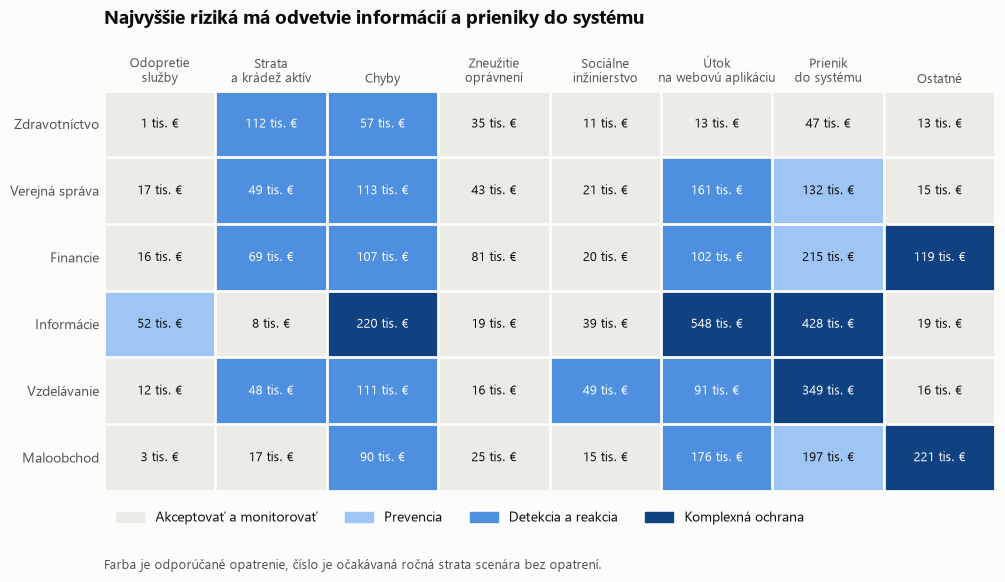

In [12]:
grid = scenarios.pivot(index="odvetvie", columns="vzor_utoku", values="opatrenie").reindex(index=SECTORS, columns=PATTERNS)
losses = scenarios.pivot(index="odvetvie", columns="vzor_utoku", values="očakávaná strata (€)").reindex(index=SECTORS, columns=PATTERNS)
codes = grid.replace({name: index for index, name in enumerate(OPTION_NAMES)}).to_numpy(dtype=int)

fig, ax = plt.subplots(figsize=(11.5, 5.2))
ax.imshow(codes, cmap=ListedColormap(OPTION_COLORS), vmin=-0.5, vmax=3.5, aspect="auto")
for row in range(codes.shape[0]):
    for column in range(codes.shape[1]):
        ax.text(column, row, f"{losses.iloc[row, column] / 1000:,.0f} tis. €".replace(",", " "),
                ha="center", va="center", fontsize=9, color=OPTION_TEXT[codes[row, column]])
ax.set_xticks(np.arange(len(PATTERNS) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(SECTORS) + 1) - 0.5, minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="both", length=0)
ax.set_xticks(range(len(PATTERNS)), [pattern.replace(" ", "\n", 1) for pattern in PATTERNS], fontsize=9)
ax.set_yticks(range(len(SECTORS)), SECTORS)
ax.xaxis.tick_top()
ax.spines[:].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in OPTION_COLORS]
ax.legend(handles, OPTION_NAMES, ncols=4, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.02))
ax.set_title("Najvyššie riziká má odvetvie informácií a prieniky do systému", loc="left", fontsize=14, fontweight="bold", pad=48)
ax.text(0, -0.17, "Farba je odporúčané opatrenie, číslo je očakávaná ročná strata scenára bez opatrení.",
        transform=ax.transAxes, color=INK_SECONDARY, fontsize=9.5, va="top")
fig.savefig(FIGURES_DIR / "7_register_rizik.png")
plt.show()

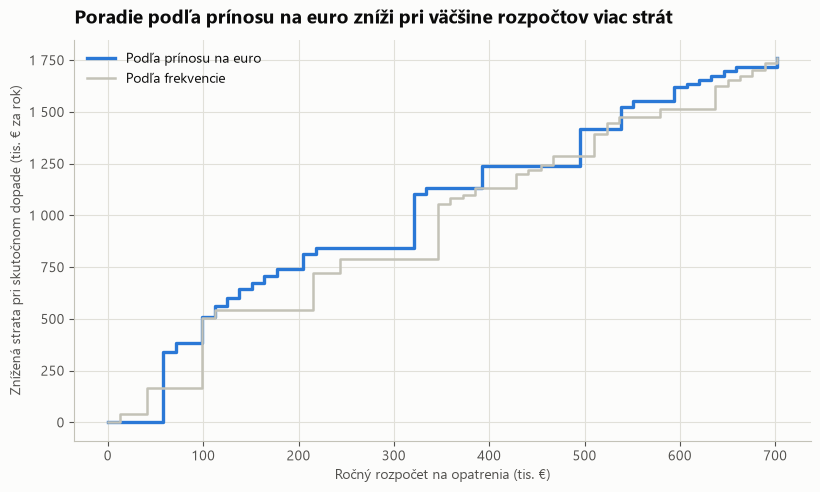

In [13]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for (name, (spent, reduced)), color in zip(curves.items(), [BLUE, NEUTRAL]):
    ax.step(spent / 1000, reduced / 1000, where="post", color=color, linewidth=2.4 if color == BLUE else 1.8, label=name)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}".replace(",", " "))
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}".replace(",", " "))
ax.set_xlabel("Ročný rozpočet na opatrenia (tis. €)")
ax.set_ylabel("Znížená strata pri skutočnom dopade (tis. € za rok)")
ax.set_title("Poradie podľa prínosu na euro zníži pri väčšine rozpočtov viac strát", loc="left", fontsize=14, fontweight="bold", pad=12)
fig.savefig(FIGURES_DIR / "8_rozpocet.png")
plt.show()

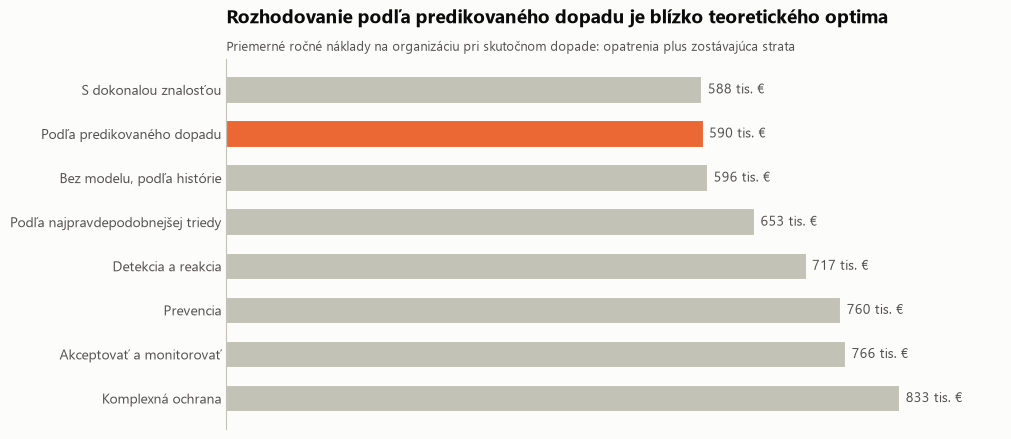

In [14]:
plot_table = comparison.sort_values(ascending=False) / len(SECTORS)
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = [ORANGE if name == STRATEGY_OURS else NEUTRAL for name in plot_table.index]
bars = ax.barh(plot_table.index, plot_table, height=0.62, color=colors, edgecolor=SURFACE, linewidth=1.5)
ax.bar_label(bars, labels=[f"{value / 1000:,.0f} tis. €".replace(",", " ") for value in plot_table], padding=4, color=INK_SECONDARY)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(length=0)
ax.xaxis.set_visible(False)
ax.set_xlim(0, plot_table.max() * 1.15)
ax.set_title("Rozhodovanie podľa predikovaného dopadu je blízko teoretického optima", loc="left", fontsize=14, fontweight="bold", pad=26)
ax.text(0, 1.015, "Priemerné ročné náklady na organizáciu pri skutočnom dopade: opatrenia plus zostávajúca strata",
        transform=ax.transAxes, color=INK_SECONDARY, fontsize=9.5, va="bottom")
fig.savefig(FIGURES_DIR / "9_porovnanie_strategii_rizik.png")
plt.show()

## 8. Uloženie registra rizík

In [15]:
register = scenarios.sort_values(["priorita", "očakávaná strata (€)"], ascending=[True, False]).copy()
register["priorita"] = register["priorita"].replace(0, pd.NA)
register.round(4).to_csv(REGISTER_PATH, index=False, encoding="utf-8")
print(f"Uložené: {REGISTER_PATH}, scenáre: {len(register)}")

Uložené: data\processed\vcdb_register_rizik.csv, scenáre: 48


## 9. Zhrnutie a odporúčania

Výsledky platia pre 48 scenárov rizika v 6 odvetviach. Dopad scenárov bol odhadnutý z 1 052 testovacích incidentov, ktoré model pri učení nevidel. Finančné hodnoty vychádzajú z predpokladov v časti 2, preto sú dôležité najmä poradie stratégií a prahy, nie absolútne sumy.

| Opatrenie | Kedy sa odporúča | Scenáre | Zdôvodnenie |
| --- | --- | ---: | --- |
| **Akceptovať a monitorovať** | očakávaná strata do 35 až 117 tisíc € ročne podľa vzoru útoku | 24 | Každé ďalšie opatrenie stojí aspoň 15 tisíc € ročne a pri nízkej strate sa nevráti. |
| **Prevencia** | najmä prienik do systému a odopretie služby so strednou stratou | 4 | Pri týchto vzoroch je detekcia drahá, napríklad sieťový monitoring CIS 13, takže je výhodnejšie znížiť počet incidentov. |
| **Detekcia a reakcia** | väčšina vzorov od 39 400 € ročne | 14 | Najlacnejší zásah, ktorý zníži stratu každého incidentu. Rýchlo sa zavádza (2 mesiace), preto chráni väčšinu horizontu. |
| **Komplexná ochrana** | od 79 tisíc € (ostatné) do 317 tisíc € (prienik do systému) | 6 | Pri najväčších rizikách sa oplatí znížiť počet incidentov aj ich dopad, napriek najvyššej cene a najdlhšiemu zavedeniu. |

**Faktory.** Rozhodnutie spája riziko (pravdepodobnosť scenára × predikovaný dopad), náklady (ročná cena opatrení CIS), čas (dĺžka zavedenia znižuje účinok v trojročnom horizonte) a prioritu (poradie podľa prínosu na euro).

**Najdôležitejšie odporúčania:**

- **Odvetvie informácií:** komplexná ochrana proti útokom na webové aplikácie (očakávaná strata 548 tisíc € ročne, CIS 6, 7, 16 a 17) a proti prienikom do systému (428 tisíc €).
- **Vzdelávanie:** komplexná ochrana proti prienikom do systému (349 tisíc €).
- **Maloobchod a financie:** komplexná ochrana pri vzore ostatné, ktorý tvoria najmä skimmery na platobných termináloch, teda inventúra a kontrola zariadení (CIS 1) a reakcia na incidenty.
- **Zdravotníctvo:** detekcia a reakcia pri strate a krádeži zariadení (112 tisíc €), lebo tieto incidenty sú časté, no zvyčajne majú malý dopad.

**Výsledky:**

- Rozhodovanie podľa predikovaného dopadu stojí v priemere 589 913 € ročne na organizáciu, čo je len o 1 520 € viac ako teoretické optimum s dokonalou znalosťou dopadu.
- Najlepšia pevná stratégia, detekcia a reakcia pre všetko, stojí 717 111 €. Úspora je 17,7 %, pre 6 organizácií spolu približne 763 tisíc € ročne. 95 % interval z bootstrapu je [679 897; 833 757] €.
- Rozhodovanie iba podľa najpravdepodobnejšej triedy stojí 653 409 €. Využitie celého rozdelenia pravdepodobností ušetrí spolu približne 381 tisíc € ročne s intervalom [291 932; 594 885] €. Pri riziku záleží aj na málo pravdepodobnom, no veľmi drahom výsledku.
- Oproti rozhodovaniu bez modelu, iba podľa historického podielu tried pre odvetvie a vzor, je prínos malý: spolu približne 34 tisíc € ročne s intervalom [163; 77 117] €, teda menej ako 1 %. Na úrovni celých scenárov sa priemer predikcií blíži historickému priemeru. Model má väčší význam pri jednotlivých nových incidentoch.
- Pri ročnom rozpočte 250 tisíc € zníži poradie podľa prínosu na euro stratu o 841 tisíc €, kým poradie iba podľa frekvencie o 792 tisíc €. Pri 500 tisícoch € je to 1 418 tisíc € oproti 1 289 tisícom €.
- Vo všetkých scenároch citlivosti postup prekonal najlepšiu pevnú stratégiu, úspora bola od 6,7 % do 17,7 %.

**Obmedzenia:**

- Ceny, účinnosť opatrení a straty z incidentov sú predpoklady. Pri skutočnom použití ich treba nahradiť údajmi organizácie.
- Opatrenia sa počítajú pre každý scenár zvlášť. Mnohé opatrenia CIS, napríklad CIS 3 Data Protection, pomáhajú proti viacerým vzorom naraz, takže skutočné náklady by boli nižšie.
- Pravdepodobnosť scenárov vychádza z verejne známych incidentov a predpokladu jedného závažného incidentu ročne.
- Pri 24 zo 48 scenárov bolo v odvetví menej ako 10 testovacích incidentov daného vzoru, preto sa ich dopad odhadol iba podľa vzoru alebo zo všetkých incidentov.
- Účinky opatrení sa násobia a predpokladá sa, že nezávisia od odvetvia.